In [ ]:
from pathlib import Path
import shutil
DATA = Path.cwd() / "data"
DATA.mkdir(exist_ok=True)
expected = 'Daily steps data question one.xlsx'
if not (DATA / expected).exists():
    from google.colab import files
    print("Upload:", expected)
    uploaded = files.upload()
    if expected not in uploaded:
        raise ValueError("Please upload the file with its original name: " + expected)
    (DATA / expected).write_bytes(uploaded[expected])
print("Dataset ready:", expected)


## Execute the solution
The comments identify the operations and question parts.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

BASE = Path.cwd()
OUT = BASE / "outputs"
OUT.mkdir(exist_ok=True)
# Only the ten daily observations; exclude summary rows.
df = pd.read_excel(BASE / "data/Daily steps data question one.xlsx",
                   sheet_name="Step Data", nrows=10)
df["Date"] = pd.to_datetime(df["Date"])
steps = df["Steps"].to_numpy(dtype=int)
print("1(a) NUMPY")
print("Array:", steps)
print(f"Total: {np.sum(steps):,}")
print(f"Mean: {np.mean(steps):,.2f}")
print(f"Minimum: {np.min(steps):,}")
print(f"Maximum: {np.max(steps):,}")
print(f"Population standard deviation: {np.std(steps, ddof=0):,.2f}")
print("At least 10,000 steps:", steps[steps >= 10000])
print("\n1(b) PANDAS")
# Four processing operations, plus a missing-value check.
print("Missing values:", int(df.isna().sum().sum()))
df["Goal achieved"] = df["Steps"] >= 10000
print("Added goal column:")
print(df[["Date", "Steps", "Goal achieved"]].to_string(index=False))
print("Filtered goal days:")
print(df.loc[df["Goal achieved"], ["Date", "Steps"]].to_string(index=False))
print("Sorted by steps descending:")
print(df.sort_values("Steps", ascending=False)[
    ["Date", "Steps"]].to_string(index=False))
print("Grouped by goal status:")
print(df.groupby("Goal achieved")["Steps"].agg(["count", "mean"]))
# 1(c): chronological line chart.
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df["Date"], df["Steps"], marker="o", color="#176b60",
        label="Daily steps")
ax.axhline(10000, color="#a85b13", linestyle="--",
           label="Chosen comparison target: 10,000 steps")
ax.set(title="Daily steps from 5 to 14 October 2026",
       xlabel="Date", ylabel="Steps per day")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT / "q1_daily_steps.png", dpi=180)
plt.close(fig)
df.to_csv(OUT / "q1_processed_steps.csv", index=False)
print("\nSaved outputs/q1_daily_steps.png and q1_processed_steps.csv")


1(a) NUMPY
Array: [ 8420 10150  6730  9280 11640 14200  4980  8910 10820  7350]
Total: 92,480
Mean: 9,248.00
Minimum: 4,980
Maximum: 14,200
Population standard deviation: 2,499.76
At least 10,000 steps: [10150 11640 14200 10820]

1(b) PANDAS
Missing values: 0
Added goal column:
      Date  Steps  Goal achieved
2026-10-05   8420          False
2026-10-06  10150           True
2026-10-07   6730          False
2026-10-08   9280          False
2026-10-09  11640           True
2026-10-10  14200           True
2026-10-11   4980          False
2026-10-12   8910          False
2026-10-13  10820           True
2026-10-14   7350          False
Filtered goal days:
      Date  Steps
2026-10-06  10150
2026-10-09  11640
2026-10-10  14200
2026-10-13  10820
Sorted by steps descending:
      Date  Steps
2026-10-10  14200
2026-10-09  11640
2026-10-13  10820
2026-10-06  10150
2026-10-08   9280
2026-10-12   8910
2026-10-05   8420
2026-10-14   7350
2026-10-07   6730
2026-10-11   4980
Grouped by goal status

## 1(c) Saved visualization

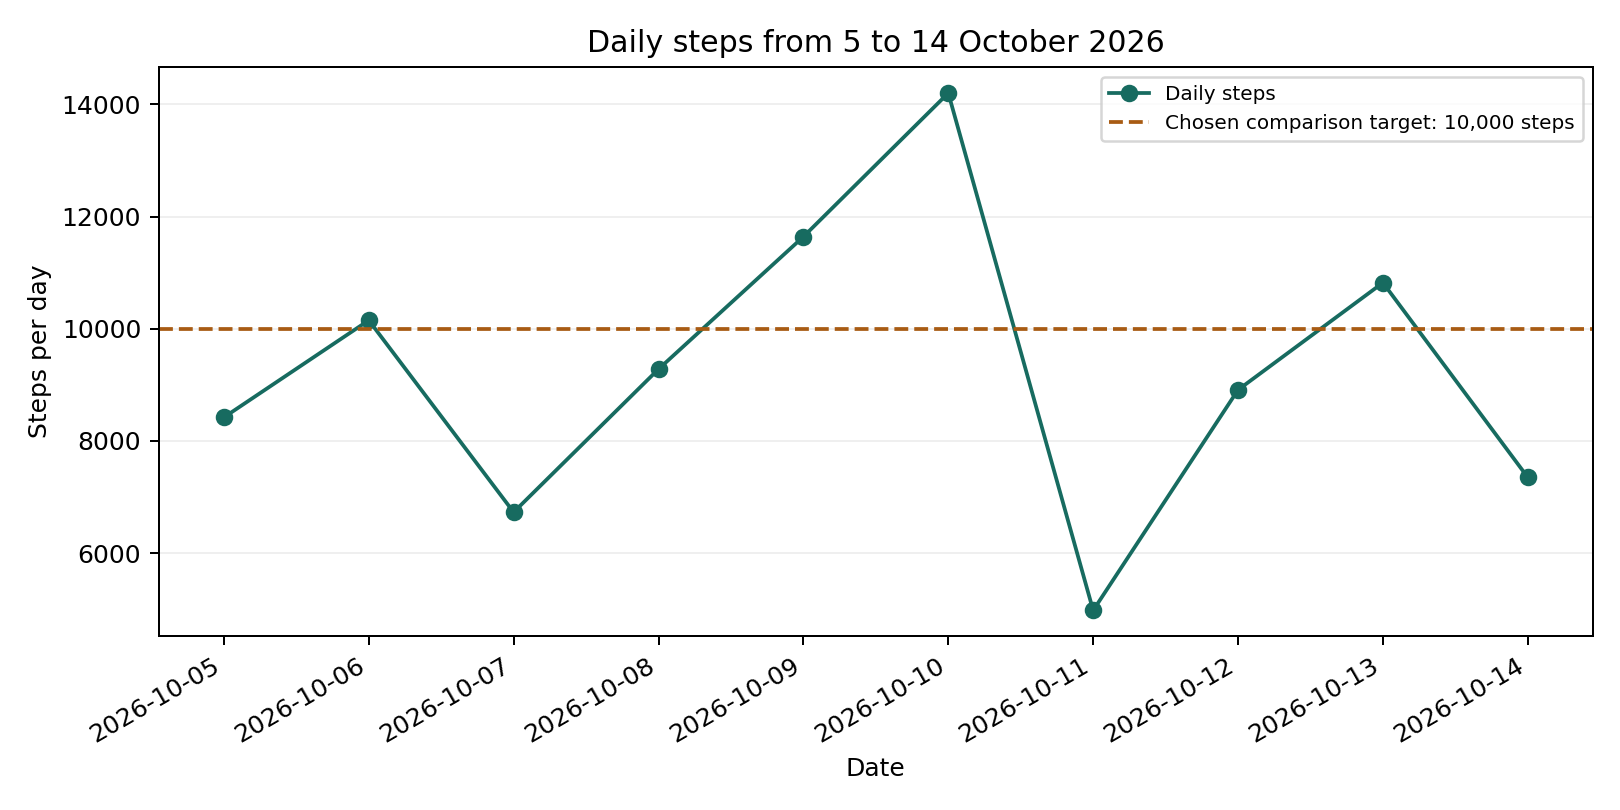

In [ ]:
from IPython.display import Image, display
display(Image(filename="outputs/q1_daily_steps.png"))

The peak is 14,200 steps on 10 October, followed by the minimum of 4,980 on 11 October. Four days meet the chosen 10,000-step target. No consistent upward or downward trend is visible over the ten days.

## Download generated files
Run this cell in Colab to download the results ZIP. Save your notebook too using **File → Download → Download .ipynb**.

In [ ]:
from google.colab import files
import zipfile
from pathlib import Path
archive = Path("question_1_results.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for path in Path("outputs").glob("*"):
        if path.is_file() and (path.name.startswith("q1_") or (1 == 4 and path.name == "student_records.json")):
            z.write(path)
    if 1 == 3:
        z.write("animals.py")
        z.write("q3_main.py")
        z.writestr("q3_output.txt", result.stdout)
files.download(str(archive))
